# 01 · Predicción de precio (CABA, departamentos en venta, USD)

Modelo A del proyecto. El pipeline completo vive en `ml/precio.py` (lo usa también la sección **Modelos** de la interfaz), así que lo que se ve acá es exactamente lo que entrena la app. Documentación: `docs/modelo_precio.md`.

1. **Datos**: `data/listings.jsonl` (última versión de cada aviso), filtro CABA.
2. **Limpieza**: reglas de consistencia, pozo/emprendimientos fuera, casi-duplicados fuera (filas en cada paso).
3. **Separación**: test fijo del 20 % **agrupado** por unidad física: la misma propiedad nunca está en train y en test.
4. **Recorte de USD/m²** (percentiles 1–99) calculado **sólo con train**, también dentro de cada fold.
5. **CV de 5 folds agrupados** en train: baselines, Ridge y grilla de LightGBM con early stopping.
6. **Evaluación única** en test, calibración del intervalo de 80 % y análisis de errores.

Kernel: el Python de `ml/.venv` (ver README, sección *Modelos*).

In [1]:
import sys, pathlib, warnings
warnings.filterwarnings('ignore')
ROOT = pathlib.Path.cwd().parent if pathlib.Path.cwd().name == 'notebooks' else pathlib.Path.cwd()
sys.path.insert(0, str(ROOT / 'ml'))
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import zpml, precio
pd.set_option('display.float_format', lambda v: f'{v:,.2f}')

P = dict(operacion='venta', currency='USD', tipo='departamento', split='agrupado', test_size=0.2, seed=42,
         cv_folds=5, tune=True, trim_pct=1.0, excluir_pozo=True)

## 1. Datos

In [2]:
df = zpml.load()          # sólo CABA, una fila por id
print(f'{len(df):,} avisos de CABA · scrape del {df.scraped_at.min()[:10]} al {df.scraped_at.max()[:10]}')
df['operacion'].value_counts()

105,413 avisos de CABA · scrape del 2026-10-15 al 2026-10-16


operacion
venta                83496
alquiler             19061
alquiler-temporal     2856
Name: count, dtype: int64

## 2. Limpieza

Reglas (constantes en `ml/precio.py`):

- superficie 18–1000 m², cubierta ≤ total; ambientes 1–10, dormitorios ≤ ambientes, baños 1–6, ≥ 9 m² por ambiente;
- precio USD 20.000–15.000.000 y USD/m² 500–15.000 (descarta pesos cargados como dólares y precios parciales);
- avisos de **pozo / en construcción / preventa / anticipo** (su precio suele ser parcial);
- expensas fuera de 200–30.000 ARS/m² y cocheras > 6 pasan a **faltante** (no se descarta el aviso);
- **casi-duplicados**: misma huella *barrio + m² + ambientes + dormitorios + baños + precio redondeado a ~2 %* (queda el más reciente).

Estas reglas son fijas (no se ajustan con los datos), así que aplicarlas antes de separar no filtra información del test.

In [3]:
d, pasos = precio.limpiar(df, P['operacion'], P['currency'], P['tipo'])
pd.DataFrame(pasos)

,paso,filas,quitadas
0,Avisos de CABA (última versión de cada id),105413,0
1,Operación = venta,83496,21917
2,Tipo = departamento,54704,28792
3,Moneda = USD,54607,97
4,Con precio y superficie,54220,387
5,Superficie entre 18 y 1000 m² y cubierta ≤ total,54097,123
6,"Ambientes 1–10, dormitorios ≤ ambientes, baños...",53979,118
7,"Precio USD 20,000–15,000,000 y USD/m² 500–15,000",53889,90
8,Sin pozo / en construcción / emprendimiento (p...,47882,6007
9,Sin casi-duplicados (barrio + m² + ambientes +...,41121,6761


pozo detectados (antes de excluir): 4876


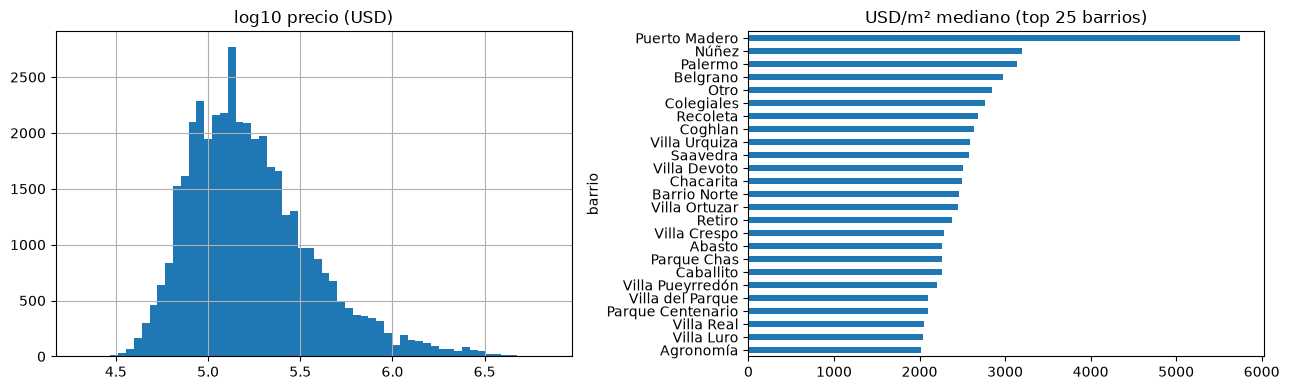

In [4]:
print('pozo detectados (antes de excluir):', precio.limpiar(df, excluir_pozo=False)[0]['pozo'].sum())
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
np.log10(d['price_x']).hist(bins=60, ax=ax[0]); ax[0].set_title('log10 precio (USD)')
d.groupby('barrio')['ppm2'].median().sort_values().tail(25).plot.barh(ax=ax[1], title='USD/m² mediano (top 25 barrios)')
plt.tight_layout()

## 3. Variables

Estructurales del aviso (superficie, ambientes, dormitorios, baños, cocheras, expensas y derivadas), barrio, y cuatro atributos que se buscan en título/descripción/etiquetas **después de borrar los montos** (a estrenar, balcón/terraza, amenities, apto crédito). El formulario de predicción pide esos cuatro como casillas.

Quedaron **afuera**: días publicado, destacado/super destacado, cantidad de fotos y tipo de publicación: describen el aviso, no la propiedad, y la predicción no los puede conocer.

In [5]:
X, nums, cats = zpml.build_features(d.reset_index(drop=True))
print('numéricas:', nums); print('categóricas:', cats)
X.isna().mean().sort_values(ascending=False).head(10).rename('faltantes')

numéricas: ['superficie_total', 'ambientes', 'dormitorios', 'banos', 'cocheras', 'expensas', 'superficie', 'log_superficie', 'expensas_m2', 'm2_por_ambiente', 'kw_a_estrenar', 'kw_balcon_terraza', 'kw_amenities', 'kw_apto_credito']
categóricas: ['barrio', 'tipo_prop']


cocheras           0.75
expensas           0.29
expensas_m2        0.29
dormitorios        0.16
banos              0.02
ambientes          0.01
m2_por_ambiente    0.01
superficie_total   0.00
log_superficie     0.00
superficie         0.00
Name: faltantes, dtype: float64

## 4–6. Separación, CV y evaluación
`precio.entrenar` hace todo el pipeline (≈ 2–3 min).

In [6]:
r = precio.entrenar(df, P)
print(f"train {len(r['tr']):,} · test {len(r['te']):,} · grupos en ambos lados: {r['grupos_compartidos']}")
pd.DataFrame(r['pasos'][-1:])

train 32,073 · test 8,392 · grupos en ambos lados: 0


,paso,filas,quitadas
0,Train: recorte de USD/m² percentiles 1–99 (cal...,32073,656


### Validación cruzada (5 folds agrupados sobre train, media ± desvío)

In [7]:
cvt = pd.DataFrame({k: {m: f"{v[m+'_media']:.2f} ± {v[m+'_std']:.2f}" for m in ['MAPE_mediana_%', 'dentro_10%_%', 'R2_log']} | {'MAE': f"{v['MAE_media']:,.0f} ± {v['MAE_std']:,.0f}"} for k, v in r['cv'].items()}).T
cvt

,MAPE_mediana_%,dentro_10%_%,R2_log,MAE
Mediana global,46.10 ± 1.28,10.74 ± 0.29,-0.03 ± 0.02,"151,047 ± 4,617"
Mediana USD/m² del barrio × m²,19.22 ± 0.34,27.16 ± 0.59,0.83 ± 0.01,"73,210 ± 2,073"
Ridge,14.70 ± 0.16,35.69 ± 0.42,0.89 ± 0.00,"59,561 ± 1,324"
LightGBM,13.62 ± 0.17,38.24 ± 0.47,0.91 ± 0.00,"53,372 ± 1,891"


In [8]:
print('Ridge alpha elegido:', r['ridge_alpha']); print('LightGBM elegido:', r['params_lgb'])
r['tuning'][['num_leaves', 'min_child_samples', 'reg_lambda', 'n_arboles_medio', 'MAPE_mediana_%_media', 'MAPE_mediana_%_std']].sort_values('MAPE_mediana_%_media')

Ridge alpha elegido: 3.0
LightGBM elegido: {'num_leaves': 63, 'min_child_samples': 10, 'learning_rate': 0.03, 'reg_lambda': 0.0, 'n_estimators': 644}


,num_leaves,min_child_samples,reg_lambda,n_arboles_medio,MAPE_mediana_%_media,MAPE_mediana_%_std
4,63,10,0.00,586,13.62,0.17
6,63,30,0.00,416,13.64,0.20
8,127,10,0.00,343,13.64,0.25
11,127,30,5.00,309,13.65,0.25
9,127,10,5.00,381,13.67,0.20
10,127,30,0.00,294,13.67,0.22
5,63,10,5.00,637,13.68,0.15
7,63,30,5.00,502,13.68,0.13
0,31,10,0.00,981,13.73,0.13
2,31,30,0.00,756,13.74,0.07


### Test (evaluación única con los hiperparámetros elegidos por CV)

In [9]:
pd.DataFrame(r['test']).T

,MAE,MAPE_mediana_%,dentro_10%_%,R2_log,R2
Mediana global,"156,994.25",48.63,9.99,-0.02,-0.08
Mediana USD/m² del barrio × m²,"73,850.54",19.34,27.68,0.85,0.66
Ridge,"61,337.98",15.05,35.22,0.90,0.74
LightGBM,"53,291.67",13.73,38.08,0.92,0.81


### Comparación con el protocolo anterior
Mismo modelo, pero **sin quitar casi-duplicados y con split aleatorio** (cómo se medía el 12,1 % original). La diferencia es el optimismo que daba tener la misma propiedad en train y en test.

In [10]:
comp = precio.comparar_aleatorio(df, P, r['params_lgb'])
print(f"test con otro aviso del mismo grupo en train: {comp['test_con_gemelo_en_train_%']:.1f} %")
pd.DataFrame({'protocolo anterior (aleatorio, con duplicados)': comp['metricas'], 'nuevo (agrupado, sin duplicados)': r['test']['LightGBM']}).T

test con otro aviso del mismo grupo en train: 72.8 %


,MAE,MAPE_mediana_%,dentro_10%_%,R2_log,R2
"protocolo anterior (aleatorio, con duplicados)","47,853.70",12.91,40.89,0.91,0.83
"nuevo (agrupado, sin duplicados)","53,291.67",13.73,38.08,0.92,0.81


### Calibración del intervalo
Los cuantiles 10/90 y 25/75 salen de los residuos **fuera de fold** del CV (train); acá se mide qué porcentaje del test cae adentro.

In [11]:
print('cuantiles (log):', {k: round(v, 3) for k, v in r['resid_log_quantiles'].items()})
print('cobertura en test:', {k: f'{v:.1f} %' for k, v in r['cobertura'].items()})

cuantiles (log): {'q10': -0.27, 'q25': -0.137, 'q50': -0.003, 'q75': 0.136, 'q90': 0.277}
cobertura en test: {'80%': '79.9 %', '50%': '49.8 %'}


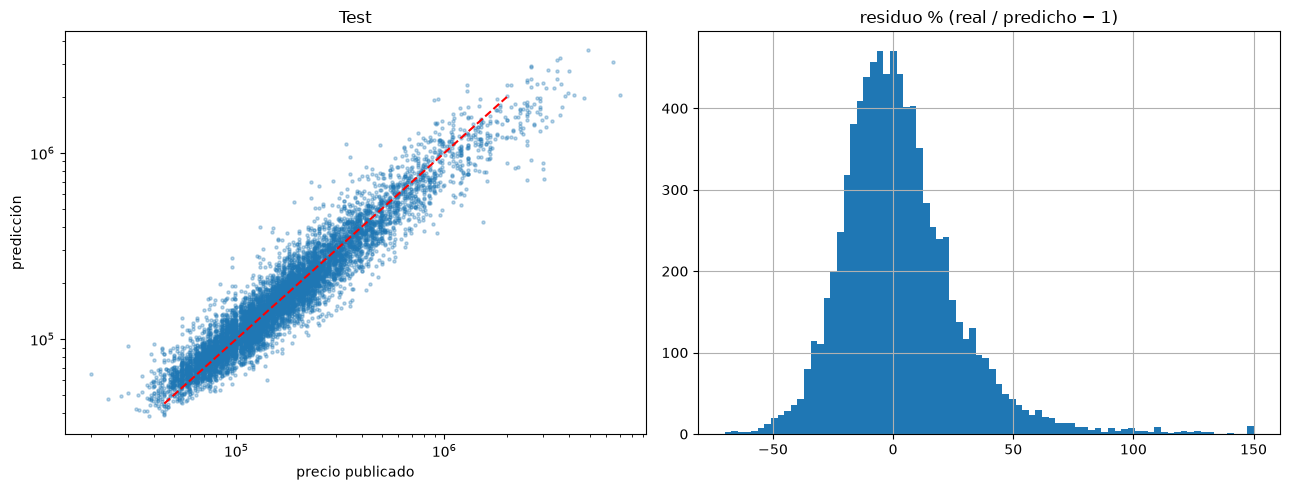

In [12]:
out = r['pred_test']
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
ax[0].scatter(out['price_x'], out['pred'], s=5, alpha=.3); lim = np.percentile(out['price_x'], [1, 99]); ax[0].plot(lim, lim, 'r--')
ax[0].set_xscale('log'); ax[0].set_yscale('log'); ax[0].set_xlabel('precio publicado'); ax[0].set_ylabel('predicción'); ax[0].set_title('Test')
out['residuo_%'].clip(-80, 150).hist(bins=80, ax=ax[1]); ax[1].set_title('residuo % (real / predicho − 1)')
plt.tight_layout()

## 7. Análisis de errores (test)
Sesgo positivo = el mercado publica más caro de lo que predice el modelo.

In [13]:
errs = precio.analisis_errores(out)
errs['superficie_m2']

,n,MAPE_mediana_%,dentro_10%_%,sesgo_mediano_%
sup,,,,
<35,"1,091.00",11.63,43.45,-0.71
35–50,"1,836.00",12.47,41.94,-0.96
50–70,"1,704.00",13.23,38.26,-1.04
70–100,"1,634.00",13.16,39.78,-0.13
100–150,"1,149.00",15.91,32.11,0.49
150+,978.00,18.02,28.73,0.89


In [14]:
errs['precio_usd']

,n,MAPE_mediana_%,dentro_10%_%,sesgo_mediano_%
price_x,,,,
<80k,"1,485.00",13.86,37.04,-10.61
80–120k,"1,771.00",12.04,42.18,-2.45
120–180k,"1,767.00",12.14,43.69,-0.26
180–300k,"1,700.00",14.07,37.59,3.80
300–600k,"1,064.00",15.66,32.14,7.88
600k+,605.00,20.95,24.13,17.33


In [15]:
errs['barrio']   # barrios con ≥ 30 avisos en test, de menor a mayor error

,n,MAPE_mediana_%,dentro_10%_%,sesgo_mediano_%
barrio,,,,
La Paternal,43.00,7.82,67.44,-2.83
Villa Pueyrredón,40.00,8.43,52.50,-2.59
Villa del Parque,151.00,8.85,54.30,-1.08
Coghlan,70.00,10.20,50.00,4.19
Villa Santa Rita,67.00,10.50,47.76,-1.84
Villa Urquiza,257.00,10.62,46.69,0.40
Villa Devoto,185.00,10.79,48.11,1.32
Parque Patricios,50.00,11.04,40.00,-2.96
Almagro,259.00,11.38,44.02,1.36


## 8. Explicación (importancia y SHAP)

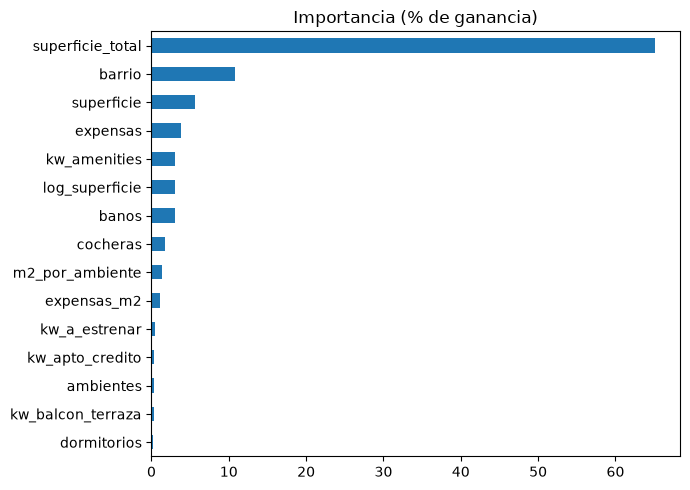

In [16]:
g = r['gbm']
imp = pd.Series(g.booster_.feature_importance('gain'), index=g.feature_name_).sort_values()
(imp / imp.sum() * 100).tail(15).plot.barh(figsize=(7, 5), title='Importancia (% de ganancia)'); plt.tight_layout()

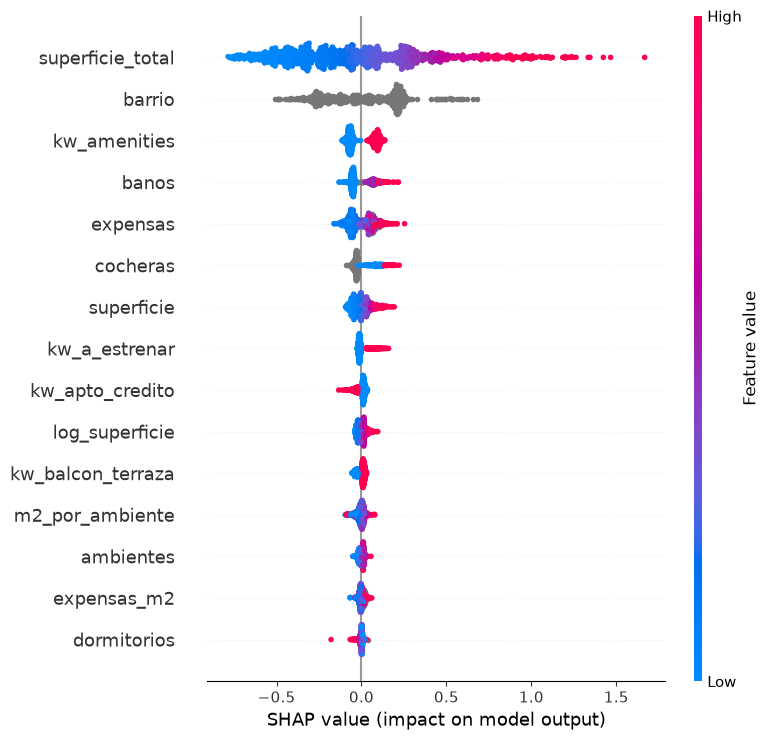

In [17]:
try:
    import shap
    Xte = precio.fijar_categorias(r['X'].iloc[r['te']], r['cats'], r['levels'])
    sample = Xte.sample(1000, random_state=0)
    shap.summary_plot(shap.TreeExplainer(g).shap_values(sample), sample, max_display=15)
except Exception as e:
    print('SHAP no disponible:', e)

## 9. Conclusiones

Ver `docs/modelo_precio.md`: métricas finales, limitaciones (precios publicados, no de cierre; fecha del scrape; dólar MEP) y cómo reproducir.